<a href="https://colab.research.google.com/github/RoqueThis/MachineLearning/blob/main/Roquemore_starter_bikes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import polars as pl
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import keras.backend as K
from keras.callbacks import Callback
from plotnine import ggplot, aes, geom_boxplot, labs, theme_bw, element_text, scale_x_discrete, geom_dotplot, geom_line, geom_point, theme, geom_smooth, facet_grid

In [4]:
# Data Visualization
data = pl.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes.csv')

pl.Config.set_tbl_rows(-1)          # show all rows
pl.Config.set_tbl_cols(-1)          # show all columns
pl.Config.set_tbl_width_chars(-1)   # no width truncation

print(data.describe())
print(data.head())

shape: (9, 13)
┌────────────┬──────────┬───────────┬────────────┬────────────┬───────────┬──────────────┬──────────┬───────────┬────────────┬──────────┬──────────┬────────────┐
│ statistic  ┆ dteday   ┆ hr        ┆ casual     ┆ registered ┆ temp_c    ┆ feels_like_c ┆ hum      ┆ windspeed ┆ weathersit ┆ season   ┆ holiday  ┆ workingday │
│ ---        ┆ ---      ┆ ---       ┆ ---        ┆ ---        ┆ ---       ┆ ---          ┆ ---      ┆ ---       ┆ ---        ┆ ---      ┆ ---      ┆ ---        │
│ str        ┆ str      ┆ f64       ┆ f64        ┆ f64        ┆ f64       ┆ f64          ┆ f64      ┆ f64       ┆ f64        ┆ f64      ┆ f64      ┆ f64        │
╞════════════╪══════════╪═══════════╪════════════╪════════════╪═══════════╪══════════════╪══════════╪═══════════╪════════════╪══════════╪══════════╪════════════╡
│ count      ┆ 112475   ┆ 112475.0  ┆ 112475.0   ┆ 112475.0   ┆ 112475.0  ┆ 112475.0     ┆ 112475.0 ┆ 112475.0  ┆ 112475.0   ┆ 112475.0 ┆ 112475.0 ┆ 112475.0   │
│ null_count 

In [ ]:
# Add Potentially Significant Data
HOLIDAYS = {
    "new_year": {
        "avg_date": "01-01"
    },
    "presidents_day": {
        "avg_date": "02-16"
    },
    "memorial_day": {
        "avg_date": "05-26"
    },
    "mothers_day": {
        "avg_date": "05-10"
    },
    "fathers_day": {
        "avg_date": "06-17"
    },
    "independence_day": {
        "avg_date": "07-04"
    },
    "labor_day": {
        "avg_date": "09-07"
    },
    "veterans_day": {
        "avg_date": "11-11"
    },
    "thanksgiving": {
        "avg_date": "11-26"
    },
    "black_friday": {
        "avg_date": "11-27"
    },
    "christmas": {
        "avg_date": "12-25"
    }
}

In [5]:
# Data Cleaning
bikes = pl.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes.csv')
bikes = bikes.with_columns((pl.col('casual') + pl.col('registered')).alias('total'))

# Consider Building a feature using registered % to casual to contrast with working days.
# Consider Revamping holiday, remove old and have days till next relevant holdiday using info from above
# you can also weigh the holidays but that may be too much.
# Consider adding year, and month and day from the date
# Consider sin cos the seasons and months.
# Consider normalizing data, minmax or a zscore (highlights outliers more) for example on temp and humitidy

# using sine and cosine with time (took a bit)
bikes = bikes.with_columns([
    (2 * np.pi * pl.col('hr') / 24.0).sin().alias('hr_sin'),
    (2 * np.pi * pl.col('hr') / 24.0).cos().alias('hr_cos')
]).drop('hr')

bikes_pro = bikes.to_dummies(columns=['season', 'weathersit'])

In [15]:
# Setting up the Model
exclude_cols = ['total','casual', 'registered', 'dteday']

target_col = 'total'
feature_cols = [c for c in bikes_pro.columns if c not in exclude_cols]

X = bikes_pro.select(feature_cols).to_numpy()
y = bikes_pro.select(target_col).to_numpy().ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Models
model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='linear')
])

# Consider groking, 10,000 epoch training and remove early stopping. it will memorize then generalize, Weird but sometimes effective
# Have a learning rate schedule
# Use a Tuner to test optimizers, learning rate, and layers (Swish or LeakyRelu instead of Relu, AdamW vs just Adam)
# keras-tuner is prebuilt for it. https://keras.io/keras_tuner/
# End with 2 outputs 1 casual and 1 registered. That will help the weights backpropogate to distiguish as there will be different
# behavioral patterns. Also note with 2 outputs have at least columns x 2 as the layer prior to output. You shouldnt need 512 tho...
# You can also make 2 seperate networks or Heads for each. like having 1 layer of 256 that feeds into 2 layers of 64 that both feed into 1.
# Then you can track the error for both seperatly
# Try loss=tf.keras.losses.Huber(delta=1.0), A loss function built to handle spikes a little better

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mean_squared_error',
    metrics=['mean_absolute_error', keras.metrics.RootMeanSquaredError(name='rmse')]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.5,
    epochs=150,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/150
703/703 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - loss: 54729.2539 - mean_absolute_error: 149.6648 - rmse: 233.9428 - val_loss: 29682.7656 - val_mean_absolute_error: 111.8044 - val_rmse: 172.2869
Epoch 2/150
703/703 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 30188.3320 - mean_absolute_error: 113.4921 - rmse: 173.7479 - val_loss: 26754.3184 - val_mean_absolute_error: 105.2149 - val_rmse: 163.5675
Epoch 3/150
703/703 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 29029.3535 - mean_absolute_error: 111.3137 - rmse: 170.3800 - val_loss: 26337.4473 - val_mean_absolute_error: 102.9282 - val_rmse: 162.2882
Epoch 4/150
703/703 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 28595.3047 - mean_absolute_error: 109.6530 - rmse: 169.1015 - val_loss: 25816.7441 - val_mean_absolute_error: 103.3019 - val_rmse: 160.6759
Epoch 5/150
703/703 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 27957.8086 - mean_absolute_error: 108.4752 - rmse: 167.2059 - val_loss: 25581.6035 - val_mean_absolute_error: 102.6698 - val_rmse: 

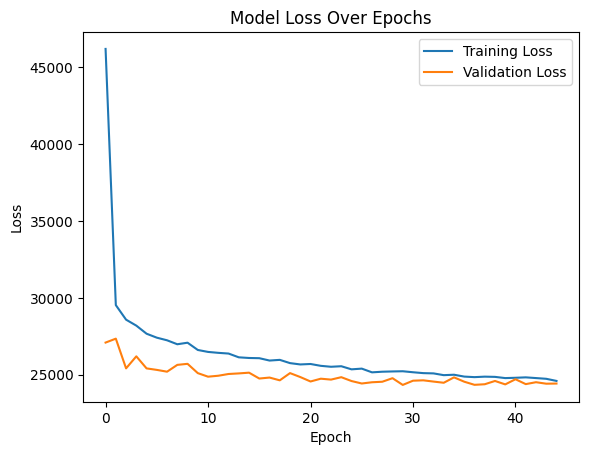

In [ ]:
plt.plot(history.history['loss'], label='Training Loss')
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model Loss Over Epochs')
plt.legend()
plt.show()

In [ ]:
# Output
test_metrics = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Model Output")
print(f"MAE:  {test_metrics[1]:.2f} bikes")
print(f"RMSE: {test_metrics[2]:.2f} bikes")

Model Output
MAE:  98.62 bikes
RMSE: 156.64 bikes


In [10]:
# Graphs

bikes = bikes.with_columns([
    pl.when(pl.col('holiday') == 1).then(pl.lit('Holiday')).otherwise(pl.lit('Not Holiday')).alias('Holiday_Status'),
    pl.when(pl.col('workingday') == 1).then(pl.lit('Working Day')).otherwise(pl.lit('Non-Working Day')).alias('Work_Status')
])

bikes_pd = bikes.to_pandas()
bikes_melted = bikes_pd.melt(
    id_vars=['Holiday_Status', 'Work_Status'],
    value_vars=['casual', 'registered'],
    var_name='User_Type',
    value_name='Rentals'
)

(
    ggplot(bikes_melted, aes(x='Work_Status', y='Rentals', fill='User_Type')) +
    geom_boxplot(outlier_shape=None) +
    facet_grid('. ~ Holiday_Status') +
    labs(
        x="Type of Day",
        y="Number of Bike Rentals",
        fill="User Type",
        title="Casual vs. Registered Rentals by Day Type"
    ) +
    theme_bw()
)

#print(g)

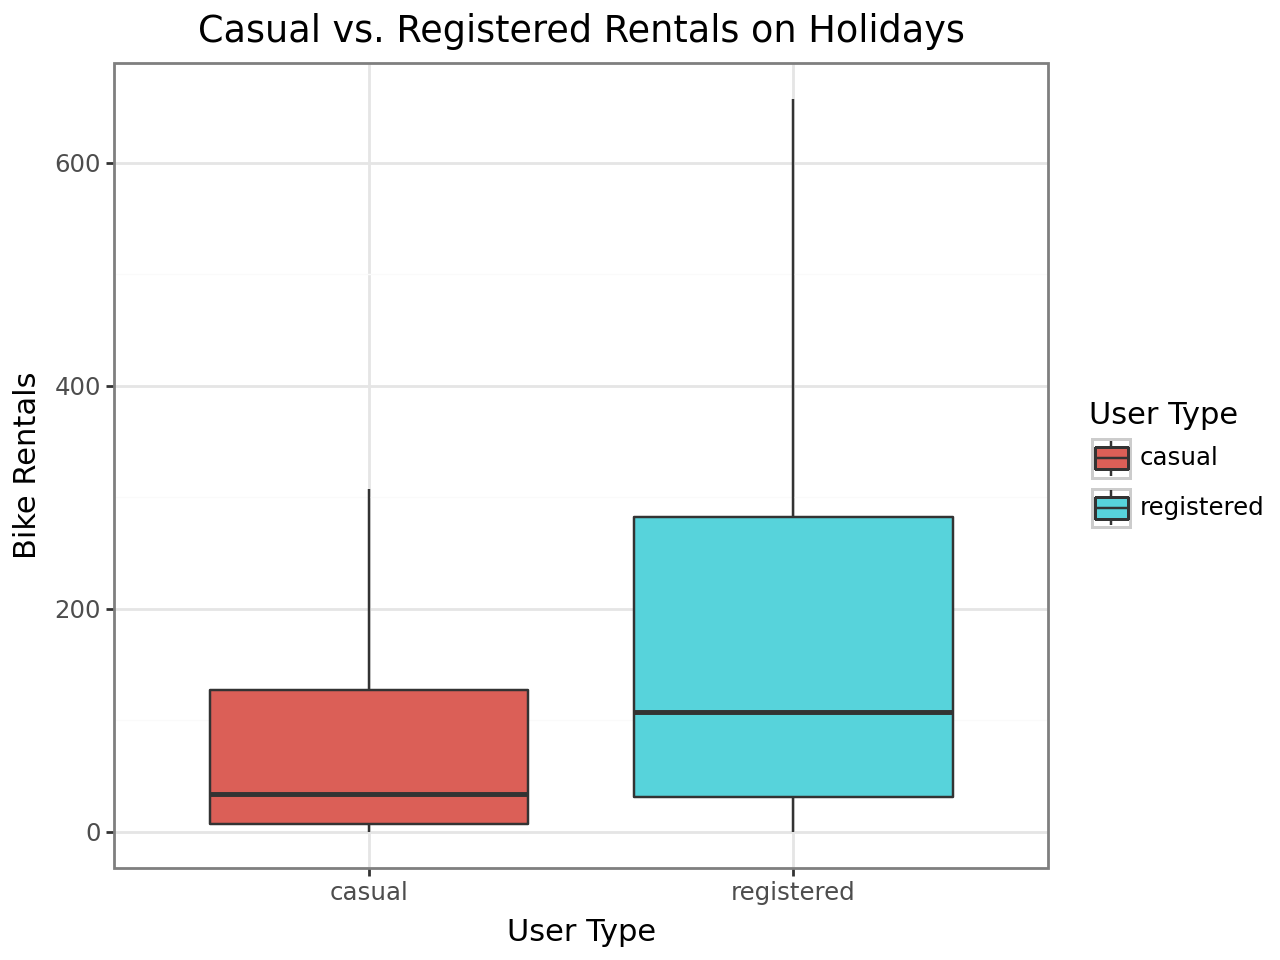

In [13]:
# Compare casual and registered user rentals on holidays
import polars as pl
from plotnine import ggplot, aes, geom_boxplot, labs, theme_bw

holiday_data = pl.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes.csv').filter(pl.col('holiday') == 1)


holiday_pd = holiday_data.to_pandas()
holiday_melted = holiday_pd.melt(
    value_vars=['casual', 'registered'],
    var_name='User_Type',
    value_name='Rentals'
)

(
    ggplot(holiday_melted, aes(x='User_Type', y='Rentals', fill='User_Type')) +
    geom_boxplot(outlier_shape=None) +
    labs(
        x="User Type",
        y="Bike Rentals",
        title="Casual vs. Registered Rentals on Holidays",
        fill="User Type"
    ) +
    theme_bw()
)



In [ ]:
bikes.glimpse()

Rows: 112475
Columns: 11
$ temp_c       <f64> 3.0, 1.7, 1.9, 2.5, 2.0, 2.7, 2.0, 1.2, 2.9, 7.0
$ feels_like_c <f64> 3.0, 1.7, 1.9, 2.5, 2.0, 1.3, 2.0, 1.2, 2.9, 7.0
$ hum          <f64> 0.7957, 0.8271999999999999, 0.8157, 0.7831, 0.8075, 0.769, 0.8131, 0.86, 0.7854000000000001, 0.7847
$ windspeed    <f64> 0.8, 0.8, 1.1, 0.8, 1.1, 5.4, 1.0, 1.0, 1.4, 2.2
$ weathersit   <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ season       <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ holiday      <i64> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0
$ workingday   <i64> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0
$ total        <i64> 16, 38, 31, 12, 1, 1, 2, 3, 8, 14
$ hr_sin       <f64> 0.0, 0.25881904510252074, 0.49999999999999994, 0.7071067811865475, 0.8660254037844386, 0.9659258262890682, 1.0, 0.9659258262890683, 0.8660254037844387, 0.7071067811865476
$ hr_cos       <f64> 1.0, 0.9659258262890683, 0.8660254037844387, 0.7071067811865476, 0.5000000000000001, 0.25881904510252096, 6.123233995736766e-17, -0.25881904510252063, -0.4999999999999998, -0.7